# Estimate variance-based input sensitivity

Level: 3. Prerequisites: Levels 1 and 2 of this topic and level 3 of learning. Reading time: 32 minutes.

## Objectives

Run the production Saltelli-Sobol sensitivity method on a bounded teaching design, rank first-order and total effects, and explain why small-design indices are exploratory estimates.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

Configure imports and record versions. This makes the method run reproducible.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path('../../../').resolve()
sys.path.insert(0, str(repo / 'data-pipeline'))
for package in ('numpy', 'scipy', 'pandas', 'matplotlib', 'nbclient', 'nbformat', 'ipykernel'):
    print(package, importlib.metadata.version(package))

numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow authors; input ranges and output definitions are persisted in `data/derived/benchmark.json` and `data/derived/contract/operating_contract.json`, MIT project licence. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

For independent uncertain inputs, first-order Sobol indices measure variance explained by one input and total indices include interactions. SALib builds the scrambled Sobol design and estimates indices; OreFlow runs every design row through the same solver. The teaching design uses a small base size to keep execution short. It is not a substitute for the production-sized sensitivity record or an empirical plant analysis.

## Current methods and evidence

Saltelli et al. (2010) give variance-based estimators for first-order and total-order effects; SALib (Herman and Usher, 2017) supplies the design and analysis implementation. OreFlow documents that its bootstrap resamples low-discrepancy design rows as independent and can overstate uncertainty bounds. The small teaching run is a reproducible method demonstration, not a novel estimator or validated field sensitivity.

Call OreFlow's production sensitivity method with a seeded, teaching-sized Sobol base design.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.methods.uncertainty import sensitivity

# Load this notebook's authored case in its fresh kernel.
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')

# Evaluate the product implementation; each factor draw is passed to the engine.
indices = sensitivity(case, case.nominal, base_samples=64, seed=20261027)
print('status:', indices['status'], '| base rows:', indices['base_samples'], '| engine evaluations:', indices['evaluations'])
print('inputs and half-widths:', indices['inputs'])

status: computed | base rows: 64 | engine evaluations: 384
inputs and half-widths: {'work_index': {'half_width': 0.2}, 'head_grade': {'half_width': 0.2}, 'liberation_size': {'half_width': 0.25}, 'floatability': {'half_width': 0.25}}


Extract first-order and total indices for recovery. Compare their order but retain their sampling uncertainty.

In [3]:
# Extract first-order and total indices for recovery.
effects = indices['indices']['recovery_pct']
if effects.get('constant'):
    print('Recovery is constant at the declared numerical tolerance; no ranking is meaningful.')
else:
    table = pd.DataFrame([{'input': name, 'first order': effects['S1'][name], 'first-order half width': effects['S1_conf'][name], 'total order': effects['ST'][name], 'total-order half width': effects['ST_conf'][name]} for name in indices['inputs']])
    display(table.sort_values('total order', ascending=False).set_index('input'))

,first order,first-order half width,total order,total-order half width
input,,,,
floatability,0.792495,0.277864,0.799238,0.220069
work_index,0.105186,0.141220,0.140280,0.068846
liberation_size,0.093664,0.090001,0.085582,0.036150
head_grade,0.004543,0.019306,0.003666,0.001483


Plot total-order effects with the reported bootstrap half-widths. Negative estimates or total below first order can arise from finite-sample error.

Interpretation boundary: simulated response under authored factor ranges; not plant causality.


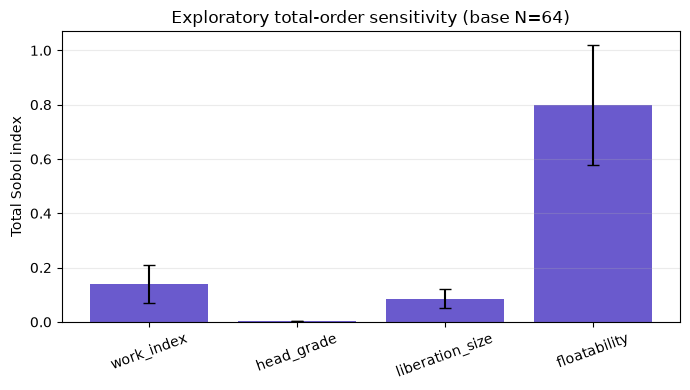

In [4]:
# Plot total-order effects with the reported bootstrap half-widths.
if not effects.get('constant'):
    names = list(indices['inputs'])
    values = np.asarray([effects['ST'][name] for name in names])
    errors = np.asarray([effects['ST_conf'][name] for name in names])
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(names, values, yerr=errors, capsize=4, color='slateblue')
    ax.set(ylabel='Total Sobol index', title='Exploratory total-order sensitivity (base N=64)')
    ax.tick_params(axis='x', rotation=20); ax.grid(True, axis='y', alpha=.25); fig.tight_layout()
print('Interpretation boundary: simulated response under authored factor ranges; not plant causality.')

## Results

The indices rank variance contributions under the assumed independent factors and the selected small sample. Overlapping or wide half-widths indicate weak separation. Sobol indices describe this model's variance structure; they are not causal effects observed in a plant.

## Summary

You ran a published variance-based sensitivity method through OreFlow's implementation. Treat the small design as a teaching experiment, and consult the larger committed analysis and its documented bootstrap limitations before quoting results.

## References

- https://doi.org/10.1016/j.cpc.2009.09.018
- https://doi.org/10.21105/joss.00097